# 03 - Desempenho: OTD por horário, trajeto e cidade

**Objetivo:** explicar onde e por que as entregas atrasam, com gráficos prontos para o relatório.

**Perguntas**
1. Em que horários o OTD cai? O efeito é igual em dias úteis e fins de semana?
2. Entregas entre cidades atrasam mais **por cruzarem a divisa** ou **por serem mais longas**?
3. Como pico de trânsito e tipo de trajeto se combinam?
4. Quais cidades de destino têm pior desempenho, e por quê?

**Base:** `data/processed/entregas_limpas.parquet` (notebook 02). KPIs de `metricas/kpis.py`; gráficos de `visualizacao/graficos.py`, salvos em `reports/figures/`.

> Lembrete: os dados são simulados. As relações abaixo refletem as regras do gerador. O valor do notebook está no **método** (como separar causas), que vale para dados reais.

## 1. Configuração

In [1]:
import sys
from pathlib import Path

import pandas as pd

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "src"))

from logistica_rotas.ingestao.leitura import carregar_entregas
from logistica_rotas.limpeza.tratamento import CAMINHO_PROCESSED, limpar_entregas, salvar_parquet
from logistica_rotas.metricas.kpis import mascara_concluidas, resumo_operacional, tabela_otd
from logistica_rotas.visualizacao import graficos as g

pd.set_option("display.float_format", "{:.1f}".format)
pd.set_option("display.width", 140)

# Se a base limpa ainda não existir (Parquet fica fora do Git), gera a partir do CSV.
if not CAMINHO_PROCESSED.exists():
    salvar_parquet(limpar_entregas(carregar_entregas()), CAMINHO_PROCESSED)
df = pd.read_parquet(CAMINHO_PROCESSED)
concl = df[mascara_concluidas(df)]
print(f"{len(df):,} pedidos | {len(concl):,} concluídos com tempo válido".replace(",", "."))

5.000 pedidos | 4.756 concluídos com tempo válido


In [2]:
resumo_operacional(df).to_frame("geral").T.astype({"pedidos": int})

,pedidos,otd_%,cancelamento_%,distancia_media_km,tempo_mediano_min,valor_medio_brl
geral,5000,92.6,4.2,5.3,15.9,14.5


## 2. Horário

### OTD por hora do pedido
Separamos dia útil e fim de semana: o pico de trânsito só existe nos dias úteis. Se o fim de semana não cair nos mesmos horários, a queda vem do trânsito e não da demanda (almoço/jantar acontecem todos os dias).

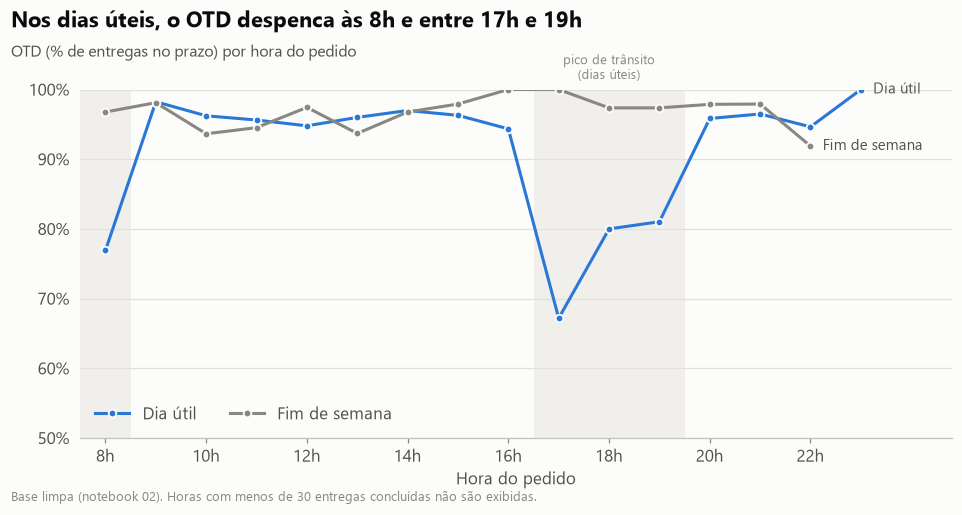

In [3]:
fig = g.otd_por_hora(df)
g.salvar_figura(fig, "01_otd_por_hora");

In [4]:
tabela_otd(df, ["dia_util", "horario_pico"]).rename(index={True: "dia útil", False: "fim de semana"})

concluidas  otd_pct
dia_util      horario_pico                     
fim de semana nao                 1335     96.9
dia útil      nao                 2485     95.9
              sim                  936     77.6

### Mapa de calor: dia da semana x hora

Mesma pergunta, com mais detalhe. Atenção ao tamanho de cada célula (nota do gráfico).

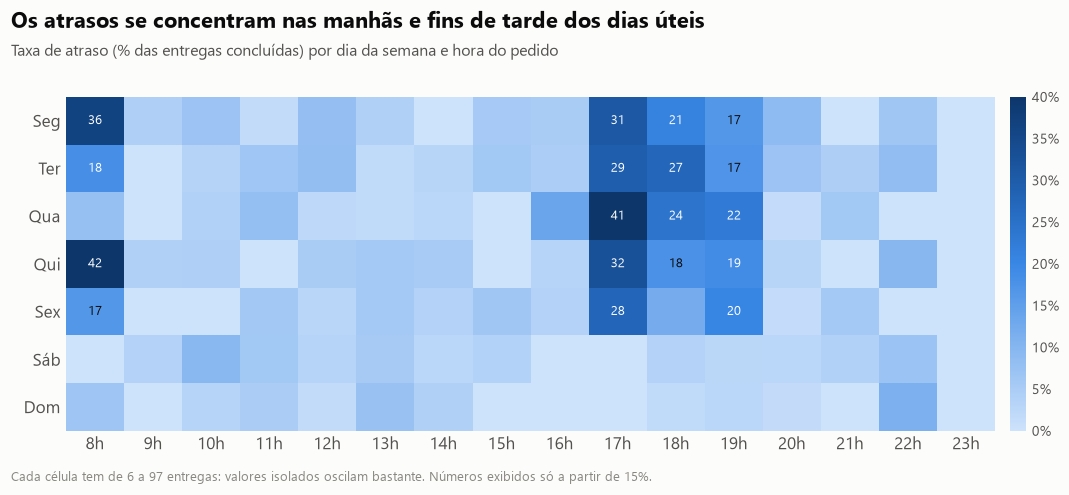

In [5]:
fig = g.mapa_calor_atraso(df)
g.salvar_figura(fig, "05_mapa_calor_atraso");

## 3. Trajeto: divisa ou distância?

No notebook 01, entregas **entre cidades** tiveram OTD bem menor. Mas elas também são **mais longas**. Para saber qual fator pesa, comparamos os dois trajetos **dentro da mesma faixa de distância** - é o mesmo raciocínio de comparar "iguais com iguais" para não confundir correlação com causa.

In [6]:
df.groupby("trajeto").apply(resumo_operacional, include_groups=False).astype({"pedidos": int})

,pedidos,otd_%,cancelamento_%,distancia_media_km,tempo_mediano_min,valor_medio_brl
trajeto,,,,,,
entre cidades,1036,84.1,4.2,11.5,31.1,24.1
mesma cidade,3964,94.8,4.2,3.7,14.0,12.0


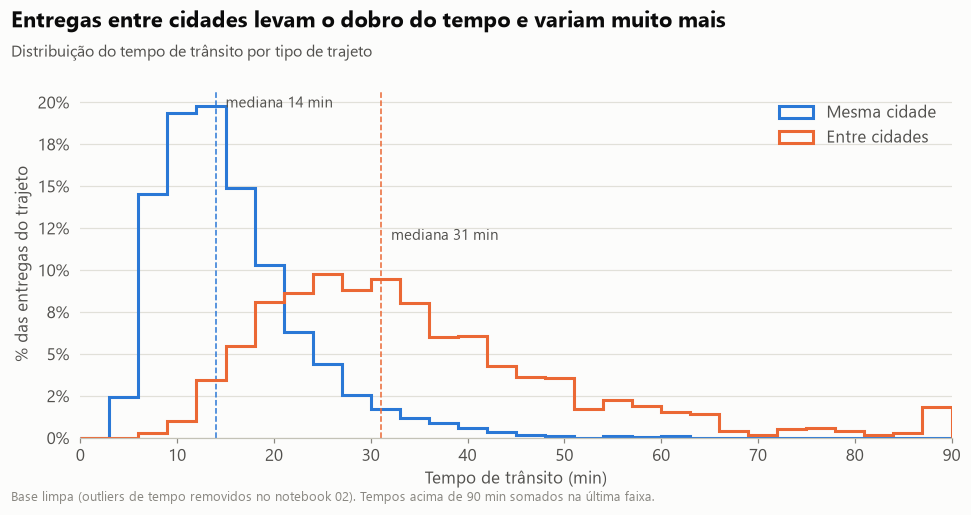

In [7]:
fig = g.distribuicao_tempo_trajeto(df)
g.salvar_figura(fig, "06_tempo_por_trajeto");

In [8]:
faixa_trajeto = tabela_otd(df, ["faixa_distancia_km", "trajeto"]).unstack()
faixa_trajeto

concluidas                    otd_pct             
trajeto            entre cidades mesma cidade entre cidades mesma cidade
faixa_distancia_km                                                      
0-2                          3.0       1035.0           NaN         99.5
2-4                         28.0       1317.0           NaN         96.7
4-6                         84.0        777.0          89.3         91.2
6-8                        128.0        383.0          90.6         91.9
8-10                       163.0        181.0          82.8         82.3
10-15                      358.0         79.0          83.8         77.2
15+                        220.0          NaN          78.2          NaN

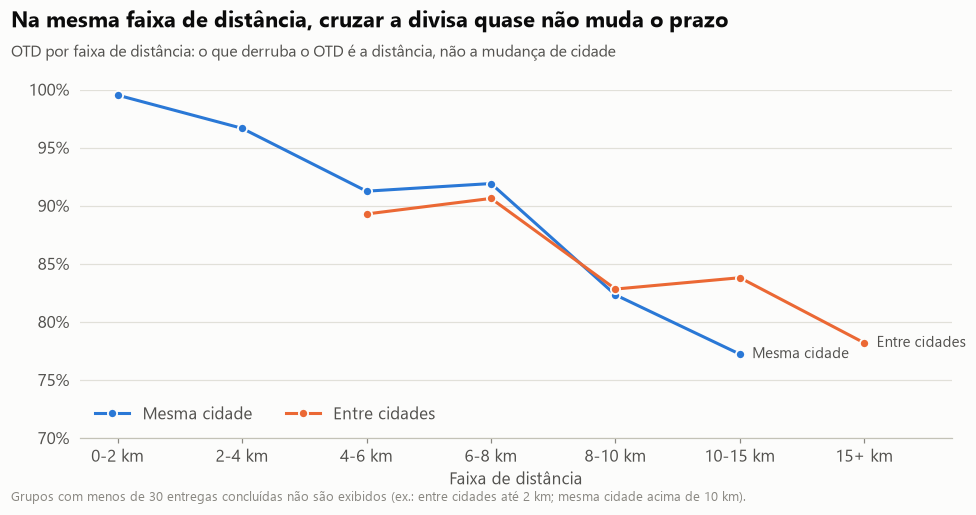

In [9]:
fig = g.otd_por_faixa_trajeto(df)
g.salvar_figura(fig, "02_otd_faixa_trajeto");

**Leitura:** dentro de cada faixa, as duas linhas ficam próximas e caem juntas conforme a distância aumenta. A diferença do resumo geral vem quase toda da **composição**: entregas entre cidades estão concentradas nas faixas longas. Isso é coerente com o gerador, que não tem nenhuma regra de "penalidade por cruzar a divisa" - o método encontrou a causa certa.

## 4. Pico x trajeto

In [10]:
tabela_otd(df, ["horario_pico", "trajeto"]).unstack()

concluidas                    otd_pct             
trajeto      entre cidades mesma cidade entre cidades mesma cidade
horario_pico                                                      
nao                    811         3009          91.1         97.6
sim                    173          763          51.4         83.5

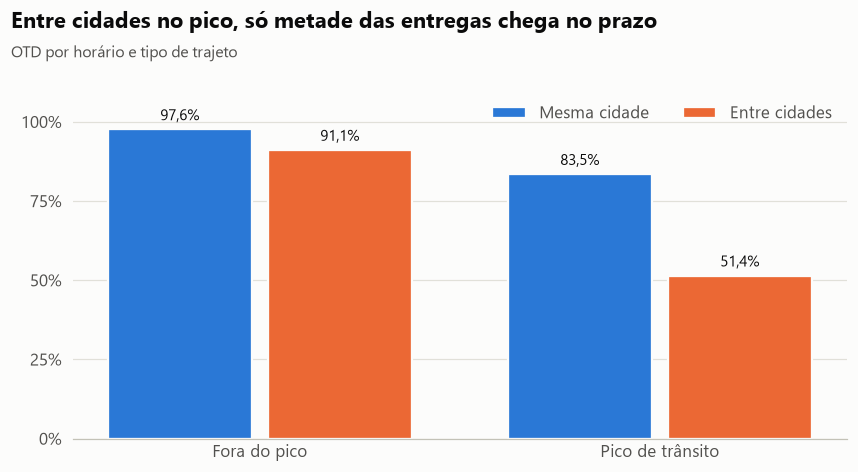

In [11]:
fig = g.otd_pico_trajeto(df)
g.salvar_figura(fig, "03_otd_pico_trajeto");

**Leitura:** os dois fatores se somam. O prazo prometido cresce com a distância (12 min + 2,5 min/km), mas **não considera o pico**. Em trajetos longos, a velocidade menor do pico consome toda a folga do prazo.

## 5. Cidade de destino

In [12]:
cidade = tabela_otd(df, ["cidade_destino", "trajeto"])["otd_pct"].unstack().add_prefix("OTD % ")
dist = (concl[concl["trajeto"] == "entre cidades"]
        .groupby("cidade_destino", observed=True)["distancia_km"].mean().rename("dist. média entre cidades (km)"))
cidade.join(dist).sort_values("dist. média entre cidades (km)")

,OTD % entre cidades,OTD % mesma cidade,dist. média entre cidades (km)
cidade_destino,,,
Santo André,87.8,95.1,9.3
São Bernardo do Campo,83.4,93.0,10.1
São Caetano do Sul,89.1,97.1,11.7
Diadema,83.2,94.2,12.6
Mauá,78.8,96.2,14.8


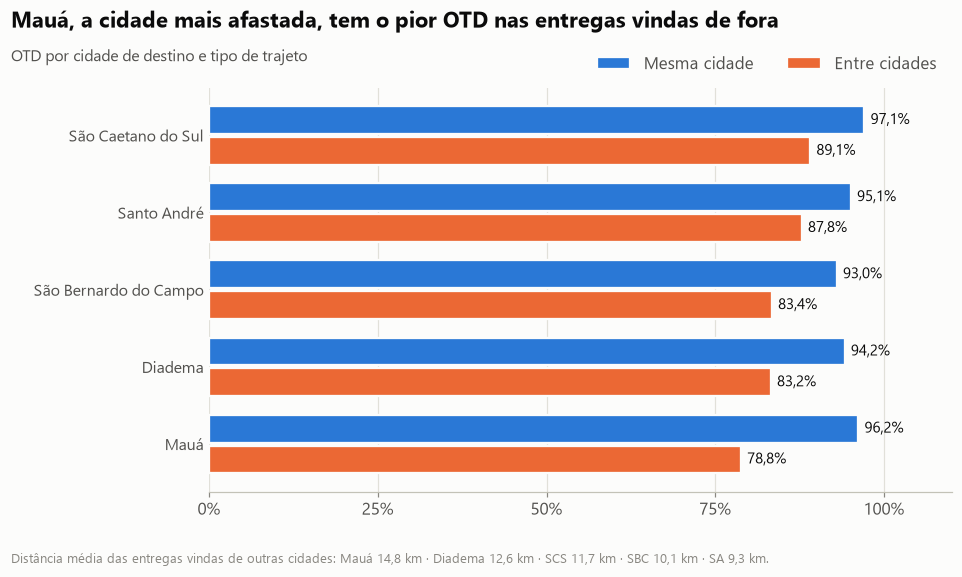

In [13]:
fig = g.otd_cidade_trajeto(df)
g.salvar_figura(fig, "04_otd_cidade_trajeto");

**Leitura:** Mauá, a cidade mais afastada (maior distância média das entregas vindas de fora), tem o pior OTD. Nas demais, a relação com a distância é fraca e as diferenças são de poucos pontos, com amostras pequenas - não dá para ranquear cidades com segurança. Dentro da própria cidade, todas ficam em 93% ou mais.

## 6. Figuras geradas

In [14]:
sorted(p.name for p in g.PASTA_FIGURAS.glob("*.png"))

['01_otd_por_hora.png',
 '02_otd_faixa_trajeto.png',
 '03_otd_pico_trajeto.png',
 '04_otd_cidade_trajeto.png',
 '05_mapa_calor_atraso.png',
 '06_tempo_por_trajeto.png',
 '07_mapa_bairros_atraso.png']

## 7. Conclusões e recomendações

**Conclusões:**
1. **O trânsito, e não a demanda, derruba o OTD.** Nos dias úteis, o OTD cai para 77,6% no pico (8h e 17h às 19h), contra 95,9% fora dele. No fim de semana, quando não há pico, o OTD é de 96,9%, e o gráfico por hora não mostra queda às 8h nem às 17h. O almoço e o jantar têm mais pedidos, mas não atrasam mais.
2. **A distância explica a diferença entre trajetos.** No geral, as entregas entre cidades têm OTD de 84,1%, contra 94,8% dentro da mesma cidade. Porém, comparando faixas de distância iguais, a diferença fica em até 2 pontos entre 4 e 10 km. Na faixa de 10 a 15 km, as entregas dentro da mesma cidade chegam a ir pior (77,2%, com só 79 entregas). Cruzar a divisa não é a causa: a causa é a entrega ser mais longa.
3. **Pico e distância se somam.** Entregas entre cidades no pico têm o pior desempenho: só 51,4% no prazo (173 entregas). A regra de prazo (12 min + 2,5 min/km) cresce com a distância, mas ignora o pico.
4. **Mauá sofre mais** com entregas vindas de outras cidades (78,8%), por ser a mais afastada (14,8 km de distância média). Nas demais cidades a relação com a distância é fraca: São Caetano recebe entregas longas (11,7 km) e tem o melhor OTD (89,1%), mas com só 129 entregas e diferenças de poucos pontos, não dá para separar o efeito do ruído.

**Recomendações (hipóteses para testar com dados reais):**
- **Prazo dinâmico:** acrescentar minutos por km no horário de pico. Simular o ganho de OTD com regras diferentes antes de aplicar.
- **Raio no pico:** priorizar entregadores próximos ou limitar o raio das entregas entre cidades nos horários de pico.
- **Monitoramento:** acompanhar o OTD por faixa de distância, e não só por cidade, para não confundir composição com desempenho.

**Próximos passos:** mapas (notebook 04) e roteirização (notebook 05).
